**Exploratory Data Analysis (EDA)**

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
 
INPUT_FILE = "cleaned_jobs.csv"
df = pd.read_csv(INPUT_FILE, parse_dates=["posted_date"])
print(f"Loaded {len(df)} rows")
df.head()

Loaded 1710 rows


,search_keyword,search_keyword_encoded,tier_label,job_title,company,location,salary_min,salary_max,salary_avg,salary_disclosed,category,contract_type,posted_date,extracted_skills,skill_count,specialized_skill_count,legacy_skill_count,description_length,job_url
0,it-support,6,legacy,IT Support Engineer- Ahmedabad (Navrangpura),Miracle HR Solution,"Ahmedabad, Gujarat",3600000.0,4800000.0,4200000.0,True,IT Jobs,Not specified,2026-05-13 02:05:51+00:00,troubleshooting; hardware; technical support; ...,4,0,4,67,https://www.adzuna.in/details/5727156528?utm_m...
1,it-support,6,legacy,We Are Hiring IT Support Executive,Global Job Placement,"Morbi, Rajkot",4200000.0,4200000.0,4200000.0,True,IT Jobs,Not specified,2026-05-15 02:01:20+00:00,NaN,0,0,0,78,https://www.adzuna.in/details/5729555287?utm_m...
2,it-support,6,legacy,IT Support Executive,RECEX,"Mumbai, Maharashtra",2880000.0,3600000.0,3240000.0,True,IT Jobs,Not specified,2026-05-13 02:05:12+00:00,cloud; hardware; technical support; installati...,5,1,4,68,https://www.adzuna.in/details/5727149345?utm_m...
3,it-support,6,legacy,IT Support Executive (Networking & Hardware),Mantras2Success,"Ahmedabad, Gujarat",2400000.0,3600000.0,3000000.0,True,IT Jobs,Not specified,2026-05-13 02:17:45+00:00,troubleshooting; hardware; ms office; maintena...,6,0,6,71,https://www.adzuna.in/details/5727275157?utm_m...
4,it-support,6,legacy,IT Support Engineer,Real Placements,"Ahmedabad, Gujarat",1200000.0,3600000.0,2400000.0,True,IT Jobs,Not specified,2026-05-13 02:06:43+00:00,troubleshooting; networking; hardware,3,0,3,66,https://www.adzuna.in/details/5727166450?utm_m...


**Summary Statistics**


In [47]:
numeric_cols = ["salary_min", "salary_max", "salary_avg", "skill_count",
                 "specialized_skill_count", "legacy_skill_count", "description_length"]
summary = df[numeric_cols].describe().round(2)
summary.index.name = "statistic"
print(summary)
 


           salary_min  salary_max  salary_avg  skill_count  \
statistic                                                    
count          552.00      552.00      552.00      1710.00   
mean        557129.35  1186521.02   871825.18         2.26   
std         688748.02  1021711.49   813755.77         2.12   
min              0.00        3.00        2.00         0.00   
25%         175000.00   500000.00   350000.00         1.00   
50%         300000.00   800000.00   600000.00         2.00   
75%         700000.00  1500000.00  1062500.00         3.00   
max        4500000.00  5500000.00  5000000.00        13.00   

           specialized_skill_count  legacy_skill_count  description_length  
statistic                                                                   
count                      1710.00             1710.00             1710.00  
mean                          1.27                0.98               71.59  
std                           1.81                1.57                9

In [48]:

print("\nMean / Median / Std by tier:")
print(df.groupby("tier_label")[["skill_count", "specialized_skill_count",
                                  "legacy_skill_count", "description_length"]]
      .agg(["mean", "median", "std"]))


Mean / Median / Std by tier:
            skill_count                  specialized_skill_count         \
                   mean median       std                    mean median   
tier_label                                                                
legacy         2.303371    2.0  2.063759                0.368290    0.0   
specialized    2.216722    2.0  2.160495                2.069307    1.0   

                      legacy_skill_count                  description_length  \
                  std               mean median       std               mean   
tier_label                                                                     
legacy       0.801837           1.935081    2.0  1.822301          70.123596   
specialized  2.060921           0.147415    0.0  0.490265          72.877888   

                               
            median        std  
tier_label                     
legacy        72.0  11.932663  
specialized   73.0   7.314177  


**Chart: Job count by tier (Bar)**

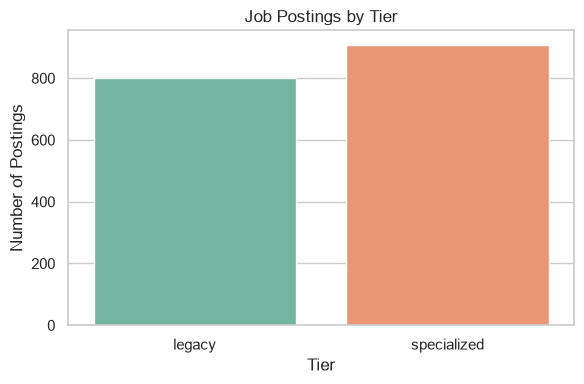

In [ ]:

 
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="tier_label", hue="tier_label", palette="Set2", legend=False)
plt.title("Job Postings by Tier")
plt.xlabel("Tier")
plt.ylabel("Number of Postings")
plt.tight_layout()
plt.savefig("chart1_job_count_by_tier.png", dpi=150)
plt.show()

**Chart: Top 15 skills overall (Bar)**

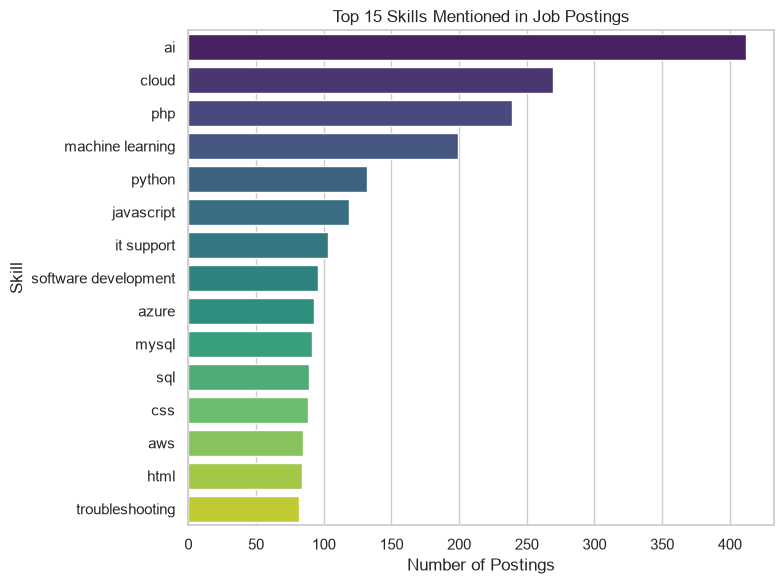

In [52]:
all_skills = (
    df["extracted_skills"]
    .dropna()
    .apply(lambda x: x.split("; ") if x else [])
    .explode()
)
all_skills = all_skills[all_skills != ""]
top_skills = all_skills.value_counts().head(15)
 
plt.figure(figsize=(8, 6))
sns.barplot(x=top_skills.values, y=top_skills.index, hue=top_skills.index,
            palette="viridis", legend=False)
plt.title("Top 15 Skills Mentioned in Job Postings")
plt.xlabel("Number of Postings")
plt.ylabel("Skill")
plt.tight_layout()
plt.savefig("chart4_top15_skills.png", dpi=150)
plt.show()

**Chart: Postings over time by tier (Line — trend analysis)**

C:\Users\nooru\AppData\Local\Temp\ipykernel_5868\471970915.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["posted_month"] = df["posted_date"].dt.to_period("M").astype(str)


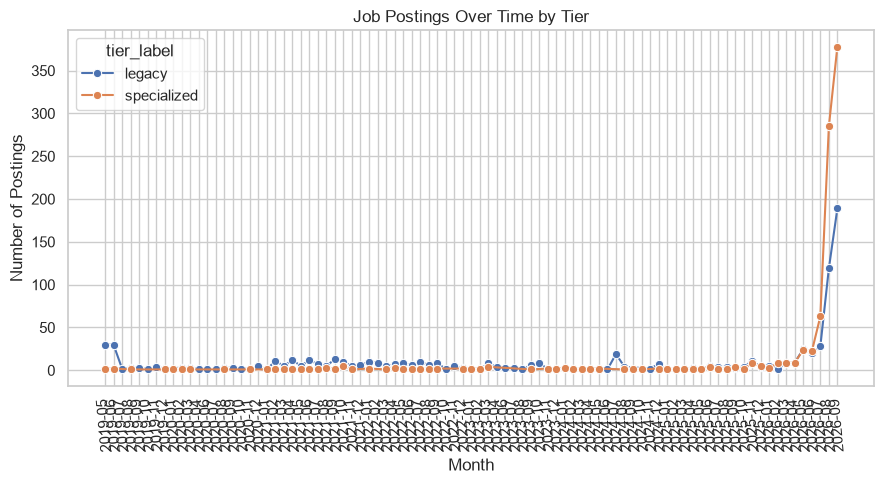

In [53]:

df["posted_month"] = df["posted_date"].dt.to_period("M").astype(str)
trend = df.groupby(["posted_month", "tier_label"]).size().reset_index(name="count")
 
plt.figure(figsize=(9, 5))
sns.lineplot(data=trend, x="posted_month", y="count", hue="tier_label", marker="o")
plt.title("Job Postings Over Time by Tier")
plt.xlabel("Month")
plt.ylabel("Number of Postings")
plt.xticks(rotation=95)
plt.tight_layout()
plt.savefig("chart5_postings_over_time.png", dpi=150)
plt.show()

**Do specialized postings ask for more skills than legacy postings?**


Specialized average skill count: 2.22
Legacy average skill count: 2.30


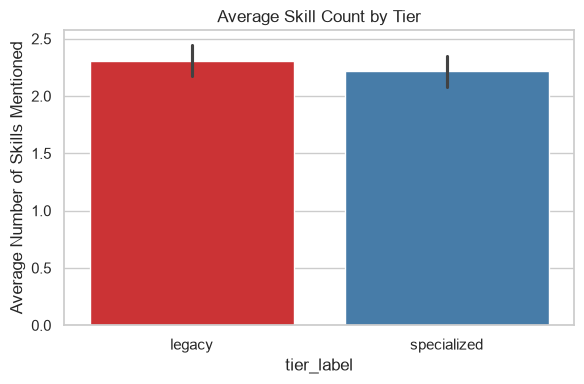

In [50]:
spec_skill_avg = df[df.tier_label == "specialized"]["skill_count"].mean()
legacy_skill_avg = df[df.tier_label == "legacy"]["skill_count"].mean()
 
print(f"Specialized average skill count: {spec_skill_avg:.2f}")
print(f"Legacy average skill count: {legacy_skill_avg:.2f}")
 
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="tier_label", y="skill_count", hue="tier_label",
            estimator="mean", palette="Set1", legend=False)
plt.title("Average Skill Count by Tier")
plt.ylabel("Average Number of Skills Mentioned")
plt.tight_layout()
plt.savefig("chart_q2_skillcount_by_tier.png", dpi=150)
plt.show()

**Explanation:** Surprisingly, the two tiers are nearly identical on raw skill
count (roughly 2.2–2.3 skills/posting each) — skill count alone does **not**
cleanly separate specialized from legacy roles. The likely cause is that
generic buzzwords (especially "AI") now appear broadly across almost all job
categories, diluting this signal. This means skill-count is a weak feature for
telling the tiers apart, even though the tiers are clearly different in pay

**Do legacy roles pay more than specialized roles, or is it the other way around?**

Specialized average salary: ₹1,478,801
Legacy average salary: ₹655,581
Gap (specialized - legacy): ₹823,221


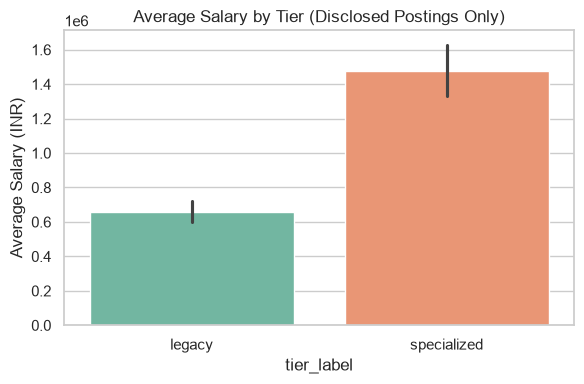

In [51]:
spec_salary_avg = disclosed[disclosed.tier_label == "specialized"]["salary_avg"].mean()
legacy_salary_avg = disclosed[disclosed.tier_label == "legacy"]["salary_avg"].mean()
gap = spec_salary_avg - legacy_salary_avg
 
print(f"Specialized average salary: ₹{spec_salary_avg:,.0f}")
print(f"Legacy average salary: ₹{legacy_salary_avg:,.0f}")
print(f"Gap (specialized - legacy): ₹{gap:,.0f}")
 
plt.figure(figsize=(6, 4))
sns.barplot(data=disclosed, x="tier_label", y="salary_avg", hue="tier_label",
            estimator="mean", palette="Set2", legend=False)
plt.title("Average Salary by Tier (Disclosed Postings Only)")
plt.ylabel("Average Salary (INR)")
plt.tight_layout()
plt.savefig("chart_q1_salary_by_tier.png", dpi=150)
plt.show()

**Explanation**:  Specialized roles (Data Scientist, AI Engineer, Cloud Engineer,
ML Engineer) pay substantially more on average than legacy roles (Software
Developer, PHP Developer, IT Support, Web Developer) — **not** the other way
around. This is based only on the ~32% of postings that disclose a salary
figure, but the gap is large enough (roughly ₹8 lakh) that it's unlikely to be
noise. This supports the "premium hiring" half of the Tech Hiring Paradox
thesis: companies are paying up for specialized talent.

**Do longer, more detailed job descriptions tend to list more skills?**

Correlation between description length and skill count: -0.241


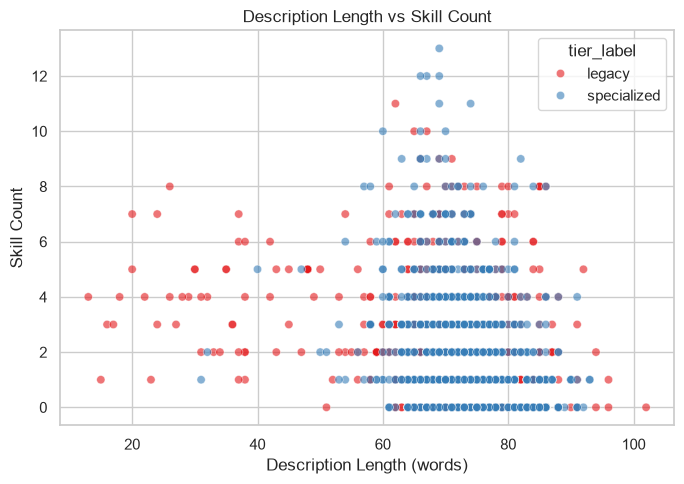

In [ ]:
correlation = df["description_length"].corr(df["skill_count"])
print(f"Correlation between description length and skill count: {correlation:.3f}")
 
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="description_length", y="skill_count",
                 hue="tier_label", alpha=0.6, palette="Set1")
plt.title("Description Length vs Skill Count")
plt.xlabel("Description Length (words)")
plt.ylabel("Skill Count")
plt.tight_layout()
plt.savefig("chart_q6_scatter_length_vs_skills.png", dpi=150)
plt.show()
 

**Explanation**: Weak, slightly negative correlation (-0.24). Most postings cluster tightly between 60-90 words regardless of tier — likely Adzuna's truncation limit, not real variation in detail. Description length isn't a useful feature here.

**How do the numeric features relate to each other overall?**

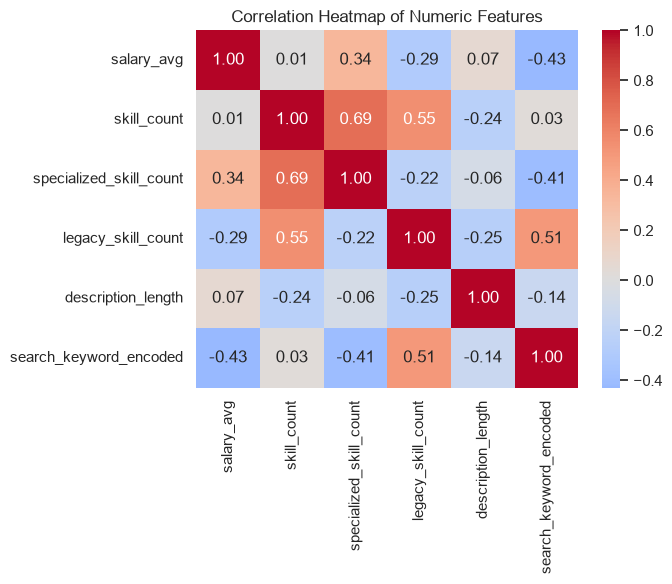

In [55]:
corr_cols = ["salary_avg", "skill_count", "specialized_skill_count",
             "legacy_skill_count", "description_length", "search_keyword_encoded"]
corr = df[corr_cols].corr()
 
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.savefig("chart7_correlation_heatmap.png", dpi=150)
plt.show()
 

**Explanation** :salary_avg correlates positively with specialized_skill_count (0.34) and negatively with legacy_skill_count (-0.29) — confirms the salary finding. But salary_avg vs total skill_count is ~0 — confirming count doesn't matter, which skills do. No correlations exceed 0.7, so features are independent enough to use together in a model.

**How transparent is the market about salary?**

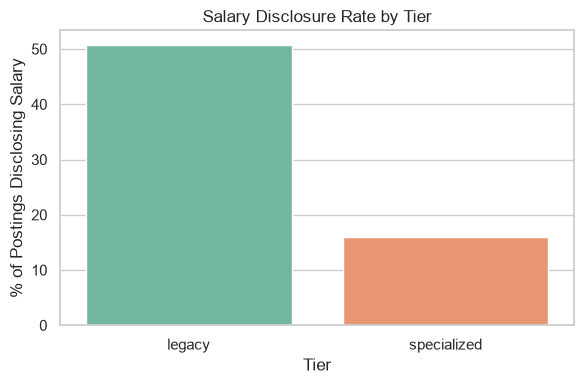

In [56]:
disclosure_rate = df.groupby("tier_label")["salary_disclosed"].mean().reset_index()
disclosure_rate["salary_disclosed"] *= 100
 
plt.figure(figsize=(6, 4))
sns.barplot(data=disclosure_rate, x="tier_label", y="salary_disclosed",
            hue="tier_label", palette="Set2", legend=False)
plt.title("Salary Disclosure Rate by Tier")
plt.xlabel("Tier")
plt.ylabel("% of Postings Disclosing Salary")
plt.tight_layout()
plt.savefig("chart8_salary_disclosure_rate.png", dpi=150)
plt.show()

**Explanation:** Only about a third of all postings disclose any salary
figure at all — a real transparency gap in the Indian tech job market. Job
seekers are frequently expected to apply, interview, and negotiate without
knowing the pay band upfront. Worth reporting as a standalone finding
alongside the main hiring-paradox thesis.

**Which specific skills dominate each tier?**

Top specialized-tier skills:
extracted_skills
ai                  378
cloud               233
machine learning    195
python               96
azure                83
data science         79
aws                  70
generative ai        51
gcp                  50
data scientist       49
Name: count, dtype: int64

Top legacy-tier skills:
extracted_skills
php                     238
javascript              115
it support              103
mysql                    89
css                      88
software development     86
html                     84
troubleshooting          70
jquery                   58
software developer       56
Name: count, dtype: int64


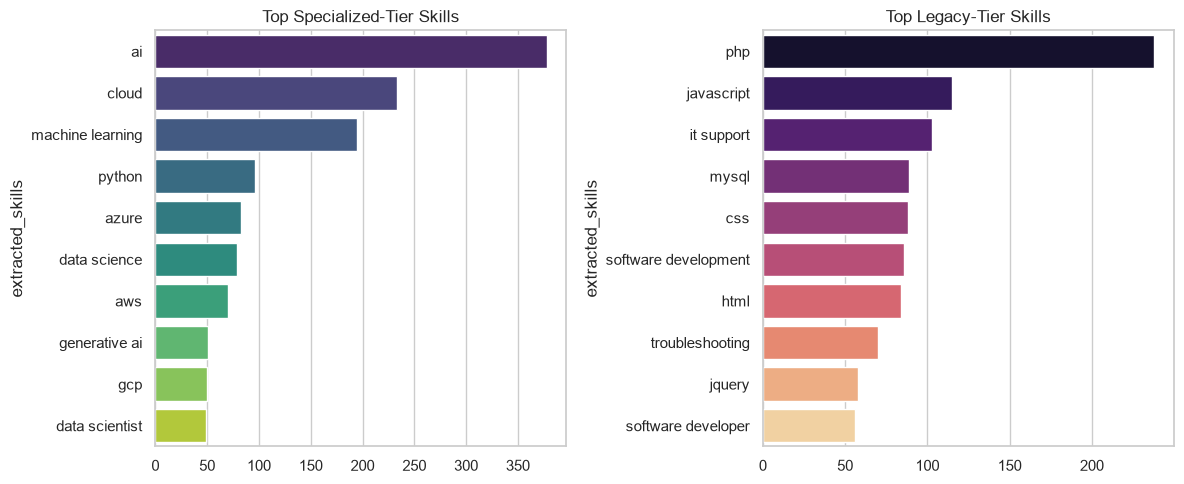

In [57]:
def top_skill_for(tier_name, n=10):
    skills = (
        df[df.tier_label == tier_name]["extracted_skills"]
        .dropna().apply(lambda x: x.split("; ") if x else [])
        .explode()
    )
    skills = skills[skills != ""]
    return skills.value_counts().head(n)
 
top_specialized = top_skill_for("specialized")
top_legacy = top_skill_for("legacy")
 
print("Top specialized-tier skills:")
print(top_specialized)
print()
print("Top legacy-tier skills:")
print(top_legacy)
 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(x=top_specialized.values, y=top_specialized.index, ax=axes[0],
            hue=top_specialized.index, palette="viridis", legend=False)
axes[0].set_title("Top Specialized-Tier Skills")
sns.barplot(x=top_legacy.values, y=top_legacy.index, ax=axes[1],
            hue=top_legacy.index, palette="magma", legend=False)
axes[1].set_title("Top Legacy-Tier Skills")
plt.tight_layout()
plt.savefig("chart_q4_top_skills_by_tier.png", dpi=150)
plt.show()

**Explanation**:The two tiers share zero overlap in their top-10 skills. Specialized postings are led by ai, cloud, and machine learning; legacy postings are led by php, javascript, and it support. So while raw skill count is nearly identical between tiers, skill identity cleanly separates them — a classifier should use which skills appear, not how many.

**Key Findings Summary**

In [58]:
spec_skill_avg = df[df.tier_label == "specialized"]["skill_count"].mean()
legacy_skill_avg = df[df.tier_label == "legacy"]["skill_count"].mean()
spec_salary_avg = disclosed[disclosed.tier_label == "specialized"]["salary_avg"].mean()
legacy_salary_avg = disclosed[disclosed.tier_label == "legacy"]["salary_avg"].mean()
 
print("=" * 60)
print("KEY FINDINGS")
print("=" * 60)
print(f"Specialized roles average {spec_skill_avg:.2f} skills/posting")
print(f"Legacy roles average {legacy_skill_avg:.2f} skills/posting")
print(f"Skill gap: {spec_skill_avg - legacy_skill_avg:.2f} skills")
print()
if not pd.isna(spec_salary_avg) and not pd.isna(legacy_salary_avg):
    print(f"Specialized avg salary (disclosed only): ₹{spec_salary_avg:,.0f}")
    print(f"Legacy avg salary (disclosed only): ₹{legacy_salary_avg:,.0f}")
    print(f"Salary gap: ₹{spec_salary_avg - legacy_salary_avg:,.0f}")
print()
print(f"Top skill overall: {top_skills.index[0]} ({top_skills.iloc[0]} postings)")
print(f"Overall salary disclosure rate: {df['salary_disclosed'].mean()*100:.1f}%")

KEY FINDINGS
Specialized roles average 2.22 skills/posting
Legacy roles average 2.30 skills/posting
Skill gap: -0.09 skills

Specialized avg salary (disclosed only): ₹1,478,801
Legacy avg salary (disclosed only): ₹655,581
Salary gap: ₹823,221

Top skill overall: ai (412 postings)
Overall salary disclosure rate: 32.3%
